# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 7</span>

### Exercise 07.1
In the NSL simulator code we have provided, include tail corrections for potential energy, $U$, and pressure $P$.

### Exercise 07.2

Use the NSL simulator code to <span style="color:red">print out **instantaneous** values of potential energy per particle, $U/N$, along **equilibrated** Monte Carlo $(N,V,T)$ and Molecular Dynamics $(N,V,E)$ simulations</span> of $M=5\times 10^5$ MC steps or MD time steps (where, for MC, the Metropolis acceptance ratio should be fixed approximately to 50% by changing the value of $dt$ that, in the MC case, represent the amplitude of the step in each direction) in the following thermodynamic conditions:
- liquid phase: $\rho^\star = 0.8$, $T^\star = 1.1$ (cut-off radius: $r^\star_c = 2.5$, for MD $dt^\star=0.001$)

Equilibration is needed both with MC and with MD. With MD, you will observe that starting from a perfect crystalline configuration the temperature, $T$, will not conserve its value. Explore and find the starting value of $T$ needed to stabilize, after a certain number of time steps (equilibration time), the average value of $T$ on the desired $T^\star$.
<span style="color:red">Perform your MC and MD simulations by re-starting after such equilibration time.</span>

1. Once this data has been produced, compute and make pictures with a python script of the autocorrelation functions of $U/N$ to approximately estimate how large the blocks in your simulations should be.
2. Use the same data to study, with a python script, the estimation of the statistical uncertainties of the expectation value of $U/N$ for different size of the blocks in the data blocking technique, from $L=M/N=10$ to $L=5\times 10^3$, being $N$ the number of blocks. Make pictures of these statistical uncertainties as a function of $L$. What you observe in the statistical uncertainties after that the block size is large enough (from the point of view of the data blocking technique)?

### Exercise 07.3

Include the calculation of the radial distribution function, $g(r)$, as a function of the radial distance $r$ among particles, with $r \in \left[ 0; L/2\right]$ inside the NSL simulator code: average value of $g(r)$ in each block, final average value of $g(r)$ with statistical uncertainties in a separate file.

### Exercise 07.4

By means of your upgraded NSL simulator code, equilibrate and <span style="color:red">perform MC NVT and MD NVE simulations via a Lennard-Jones model</span> of Argon ($\sigma = 0.34$ nm, $\epsilon/k_B = 120$ K, $m=39.948$ amu) in the following conditions:
- liquid phase: $\rho^\star = 0.8$, $T^\star = 1.1$ (cut-off radius: $r_c = 2.5$)

show in pictures the obtained average values and uncertainties for the potential energy per particle, $U/N$, the pressure $P$ and the radial distribution function $g(r)$ in LJ units ... <span style="color:red"> and compare your MC results for these quantities with those obtained via MD NVE simulations in similar thermodynamic conditions.</span>

### Supplementary activity ... just for your fun!
Note that he following **is not** part of the Numerical Exercise 7; if you had fun with exercises 7.* and you are courious, you could try to repeat exercises 7.2 and 7.4 in the following different thermodynamic conditions:
- solid phase: $\rho^\star = 1.1$, $T^\star = 0.8$ (cut-off radius: $r^\star_c = 2.2$)
- gas phase: $\rho^\star = 0.05$, $T^\star = 1.2$ (cut-off radius: $r^\star_c = 5.0$)

# <span style="color:green"> RESULTS: </span>

In this notebook we simulate the liquid state of argon with two different methods: first with the molecular dynamics (MD) as in notebook 4, and then with a Metropolis Monte Carlo (MC) simulation in the canonical ensemble. We then compare the results obtained for the pressure, the potential energy per particle and the radial distribution function $g(r)$.

### Exercise 7.1
Since the Lennard-Jones potential is truncated at the cutoff radius $r_c$, the interaction with all the particles beyond $r_c$ is neglected. To correct for this we added the tail corrections to the potential energy per particle and to the pressure. They are obtained by assuming $g(r)=1$ for $r>r_c$ and integrating the potential over that region. In reduced units we get:
$$
\frac{\langle V\rangle_{tail}}{N} = 8\pi\rho\left[\frac{1}{9\,r_c^{9}}-\frac{1}{3\,r_c^{3}}\right]
$$
$$
\langle P\rangle_{tail} = 32\pi\rho^{2}\left[\frac{1}{9\,r_c^{9}}-\frac{1}{6\,r_c^{3}}\right]
$$
Both corrections are negative, because beyond $r_c$ the attractive $r^{-6}$ term dominates over the repulsive one. To compute them, in <small><code>initialize_properties()</code></small> we added:
<small>
```cpp
_vtail = (8*M_PI*_rho)*( 1./(9*pow(_r_cut,9)) - 1./(3*pow(_r_cut,3)) );
_ptail = (32.*M_PI*_rho*_rho)*( 1./(9*pow(_r_cut,9)) - 1./(6*pow(_r_cut,3)) );
```
</small>


### Exercise 7.2
To compare the two methods, both simulations must sample the same thermodynamic state, so they have to reach the same equilibrium temperature, which we chose to be $T^*=1.1$ (for liquid argon with $N=108$ particles, $\rho^*=0.8$ and $r_c=2.5$). Since the two algorithms are controlled by different parameters, each of them was calibrated separately. For every value of the parameter we ran a simulation starting from the fcc lattice, long enough for the system to equilibrate, and measured the quantity of interest.

For the canonical ensemble (MC), the temperature is imposed directly by the Boltzmann factor in the acceptance probability, so the parameter to calibrate is the width $\delta$ of the uniform trial displacement. If $\delta$ is too small almost every move is accepted, but the system explores the configuration space very slowly. If it is too large almost every move is rejected. We ran simulations at $T^*=1.1$ with 20 blocks of 1000 steps for $\delta$ between 0.05 and 0.3 in steps of 0.025, and measured the acceptance rate in the last block. We then chose the value of $\delta$ giving an acceptance of about 50%: <small>
```cpp
for (double delta : deltas) {
    create_input_file(1, delta, 1.1, 20, 1000, 0);   // MC, T = 1.1, 20 blocks x 1000 steps
    run_simulation();
    double acc = read_final_stat_from_file("../OUTPUT/acceptance.dat");
}
```
</small>

For the microcanonical ensemble (MD), instead, the temperature is not an input, since the total energy is conserved, the temperature settles around a value that depends on the initial conditions. Starting from the lattice with random velocities, part of the initial kinetic energy is converted into potential energy during the equilibration, so the system cools down. The initial temperature $T_{start}$ must therefore be higher than the target one. We ran MD simulations with time step $dt=0.001$ and 1000 steps, for $T_{start}$ between 1.9 and 2.0 in steps of 0.01, and looked at the temperature reached at the end of the run. We then chose the $T_{start}$ for which the equilibrated temperature is $T^*=1.1$
<small>
```cpp
for (double t_start : T_starts) {
    create_input_file(0, 0.001, t_start, 1000, 1, 0);   // MD, dt = 0.001, 1000 blocks x 1 step
    run_simulation();
    double t_final = read_final_stat_from_file("../OUTPUT/temperature.dat");
}
```
</small>

The results of the two calibrations are shown in the plots that follow:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
delta, acc = np.loadtxt("./OUTPUT/CALIBRATION/acceptance_vs_delta.dat").T
t_start, t_fin = np.loadtxt("./OUTPUT/CALIBRATION/temp_correlation_md.dat").T

In [ ]:
def invert(x, y, target, window, deg=2):
    """Fit y(x) with a polynomial using only the points with |y - target| < window,
    then return the x at which the fit reaches the target value, plus the fit itself."""
    m = np.abs(y - target) < window
    p = np.polyfit(x[m], y[m], deg)
    xf = np.linspace(x[m].min(), x[m].max(), 20000) 
    return xf[np.argmin(np.abs(np.polyval(p, xf) - target))], p, xf

MC: delta   = 0.1029  (acceptance 0.5)
MD: T_start = 1.9619  (final T 1.1)


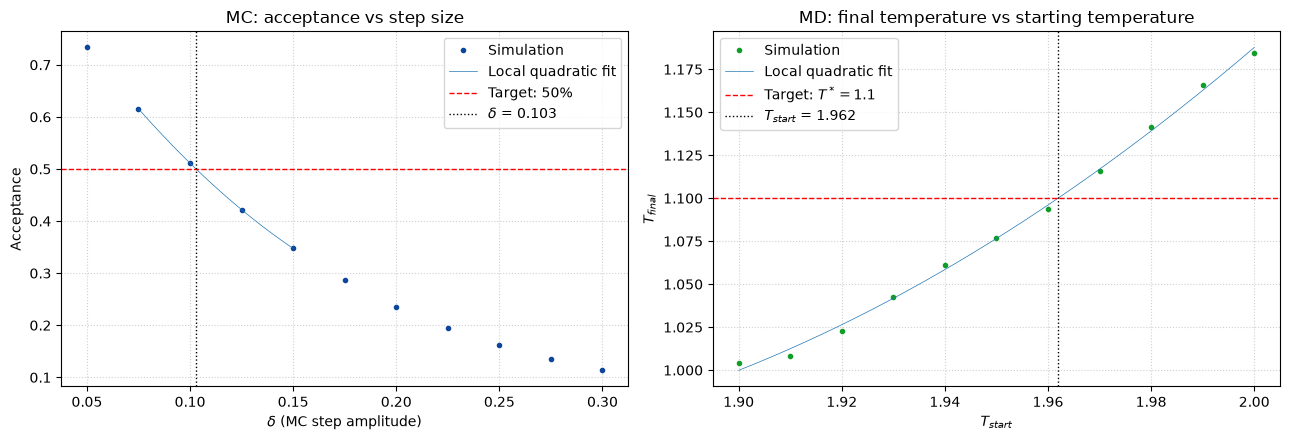

In [4]:
delta_opt, p_acc, xf_acc = invert(delta, acc, 0.5, window=0.2)    # MC: acceptance = 0.5
tstart_opt, p_T,  xf_T   = invert(t_start, t_fin, 1.1, window=0.1)    # MD: final T = 1.1
print(f"MC: delta   = {delta_opt:.4f}  (acceptance 0.5)")
print(f"MD: T_start = {tstart_opt:.4f}  (final T 1.1)")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

# MC: acceptance vs delta
axs[0].plot(delta, acc, 'o', markersize = 3, color='#0c459a', label='Simulation')
axs[0].plot(xf_acc, np.polyval(p_acc, xf_acc), '-', lw=0.5, label='Local quadratic fit')
axs[0].axhline(0.5, color='red', ls='--', lw=1, label='Target: 50%')
axs[0].axvline(delta_opt, color='black', ls=':', lw=1, label=rf'$\delta$ = {delta_opt:.3f}')
axs[0].set_xlabel(r'$\delta$ (MC step amplitude)'); axs[0].set_ylabel('Acceptance')
axs[0].set_title('MC: acceptance vs step size')

# MD: final temperature vs starting temperature
axs[1].plot(t_start, t_fin, 'o', markersize = 3,  color='#109e28', label='Simulation')
axs[1].plot(xf_T, np.polyval(p_T, xf_T), '-', lw=0.5, label='Local quadratic fit')
axs[1].axhline(1.1, color='red', ls='--', lw=1, label=r'Target: $T^*=1.1$')
axs[1].axvline(tstart_opt, color='black', ls=':', lw=1, label=rf'$T_{{start}}$ = {tstart_opt:.3f}')
axs[1].set_xlabel(r'$T_{start}$'); axs[1].set_ylabel(r'$T_{final}$')
axs[1].set_title('MD: final temperature vs starting temperature')

for ax in axs:
    ax.grid(True, ls=':', alpha=0.6); ax.legend()
plt.tight_layout()
plt.show()

The final values were obtained by fitting the data with a quadratic function, used as a simple smooth interpolation near the target, and finding where it reaches the target value: an acceptance of 50% for MC and a final temperature of 1.1 for MD. This gives $\delta=0.1029$ and $T_{start}=1.9619$.

Once the parameters were set, we simulated the system and analysed the instantaneous values of the potential energy per particle to study the correlation between successive measures. We computed the autocorrelation function
$$
C(t)=\frac{\langle x(t')\cdot x(t'+t)\rangle-\langle x\rangle^{2}}{\langle x^{2}\rangle-\langle x\rangle^{2}}
$$
where $x$ is the instantaneous potential energy per particle, $t$ is the number of steps between two measures and $\langle\cdot\rangle$ is the average over the simulation. By construction $C(0)=1$, and the time it takes to decay tells how long the correlation lasts. We summarised it in the integrated autocorrelation time
$$
\tau_{int}=\frac12+\sum_{t=1}^{W}C(t),
$$
so that roughly $2\tau_{int}$ steps are needed to obtain one independent measure. The sum is truncated at a window $W$, chosen as the first $W$ such that $W\ge c\,\tau_{int}(W)$, because for larger $t$ the function $C(t)$ is dominated by statistical noise (we used $c=20$ and, for comparison, $c=6$).

The correlation matters for the statistical uncertainty, and knowing the lenght of the correlation enable us to properly use the data blocking method. The simulation is divided into blocks of $L$ steps and the error is computed from the block averages, which are independent only if $L\gg\tau_{int}$. We then studied the error as a function of $L$ in order to choose a suitable block length for the simulation.

In [ ]:
# Instantaneous U/N along the equilibrated runs
runs = {"MC": "./OUTPUT/inst_U_MC.dat", "MD": "./OUTPUT/inst_U_MD.dat"}
U = {k: np.loadtxt(f)[:, 1] for k, f in runs.items()}

In [6]:
def autocorr(x, tmax):
    """C(t) = (<x_i x_{i+t}> - <x>^2) / (<x^2> - <x>^2), computed with FFT, C(0) = 1."""
    x = x - x.mean()
    n = len(x)
    f = np.fft.rfft(x, 2 * n)                       # zero padding avoids circular correlation
    c = np.fft.irfft(f * np.conj(f))[:tmax]
    c /= np.arange(n, n - tmax, -1)                 # divide by the number of pairs at each lag
    return c / c[0]

def tau_int(C, c=6):
    """tau = 1/2 + sum_{t=1}^{W} C(t), with W the first lag such that W >= c*tau(W) (Sokal)."""
    tau = np.cumsum(C) - 0.5
    ok = np.arange(len(C)) >= c * tau
    return tau[np.argmax(ok)] if ok.any() else tau[-1]

def blocking_error(x, L):
    """Error of the mean with blocks of L steps: sqrt((<A^2> - <A>^2) / (N - 1)), N = number of blocks."""
    N = len(x) // L
    xb = x[:N * L].reshape(N, L).mean(axis=1)       # mean of each block
    return xb.std(ddof=1) / np.sqrt(N)

MC: tau_int = 16.3 (c = 20, W = 326),  tau_int = 12.7 (c = 6),  expected plateau sigma = 7.92e-04
MD: tau_int = 35.0 (c = 20, W = 701),  tau_int = 34.1 (c = 6),  expected plateau sigma = 9.17e-04


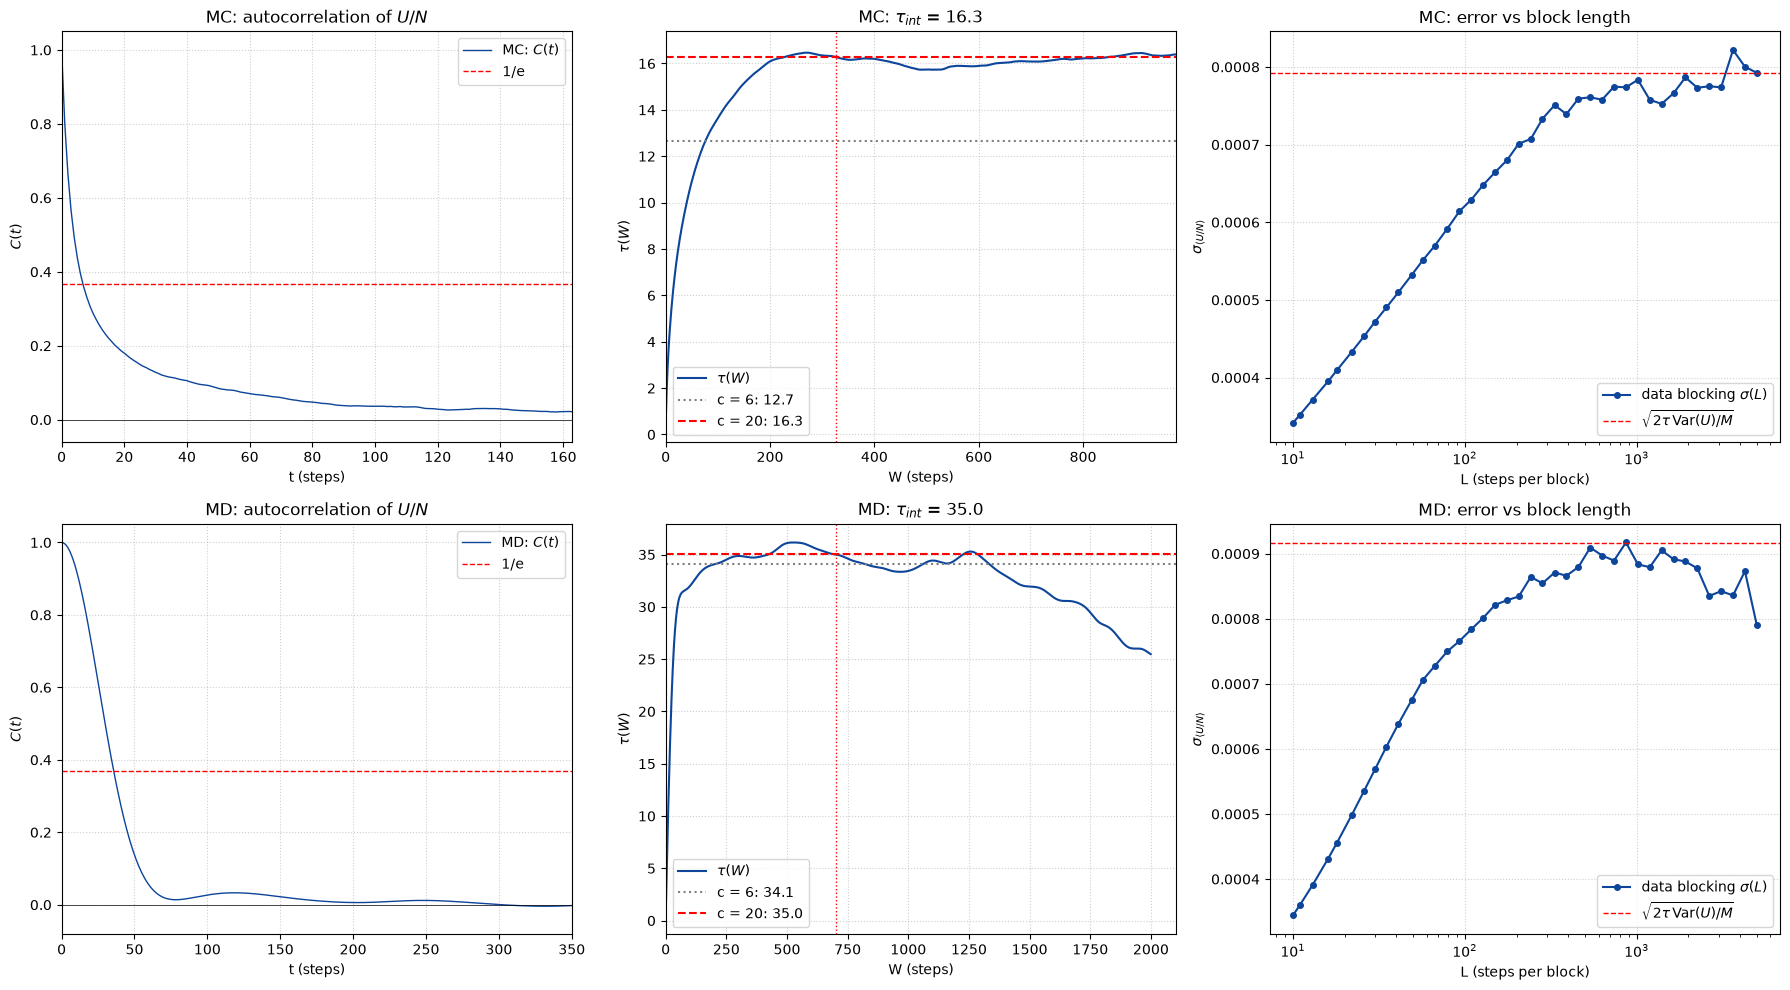

In [ ]:
c_win = 20      
tmax = 2000     
Ls = np.unique(np.logspace(1, np.log10(5000), 40).astype(int))   # L from 10 to 5e3

fig, axs = plt.subplots(2, 3, figsize=(18, 10))
for row, (name, x) in zip(axs, U.items()):
    M = len(x)
    C = autocorr(x, tmax)
    lags = np.arange(len(C))
    tau_W = np.cumsum(C) - 0.5                        # tau(W) = 1/2 + sum_{t=1}^{W} C(t)
    W = np.argmax(lags >= c_win * tau_W)              # window actually used (first W >= c*tau(W))
    tau, tau6 = tau_W[W], tau_int(C, 6)               # tau with the chosen c, and with the default c = 6
    sigma = np.array([blocking_error(x, L) for L in Ls])
    sigma_inf = np.sqrt(2 * tau * x.var() / M)        # expected plateau: error of M correlated data
    print(f"{name}: tau_int = {tau:.1f} (c = {c_win}, W = {W}),  tau_int = {tau6:.1f} (c = 6),  "
          f"expected plateau sigma = {sigma_inf:.2e}")

    # autocorrelation function (zoom on the first decay times)
    row[0].plot(lags, C, lw=1, color='#0c459a', label=rf'{name}: $C(t)$')
    row[0].axhline(0, color='k', lw=0.5)
    row[0].axhline(1 / np.e, color='red', ls='--', lw=1, label='1/e')
    row[0].set_xlim(0, 10 * tau)
    row[0].set_xlabel('t (steps)'); row[0].set_ylabel('$C(t)$')
    row[0].set_title(f'{name}: autocorrelation of $U/N$')

    # integrated autocorrelation time vs summation window
    row[1].plot(lags, tau_W, lw=1.5, color='#0c459a', label=r'$\tau(W)$')
    row[1].axhline(tau6, color='gray', ls=':', label=f'c = 6: {tau6:.1f}')
    row[1].axhline(tau, color='red', ls='--', label=f'c = {c_win}: {tau:.1f}')
    row[1].axvline(W, color='red', ls=':', lw=1)      # window used for the c = c_win estimate
    row[1].set_xlim(0, 3 * W)
    row[1].set_xlabel('W (steps)'); row[1].set_ylabel(r'$\tau(W)$')
    row[1].set_title(rf'{name}: $\tau_{{int}}$ = {tau:.1f}')

    # statistical uncertainty vs block length
    row[2].semilogx(Ls, sigma, 'o-', ms=4, color='#0c459a', label=r'data blocking $\sigma(L)$')
    row[2].axhline(sigma_inf, color='red', ls='--', lw=1, label=r'$\sqrt{2\tau\,\mathrm{Var}(U)/M}$')
    row[2].set_xlabel('L (steps per block)'); row[2].set_ylabel(r'$\sigma_{\langle U/N\rangle}$')
    row[2].set_title(f'{name}: error vs block length')

    for ax in row:
        ax.grid(True, ls=':', alpha=0.6); ax.legend()
plt.tight_layout()
plt.show()

The given graphs show, for MC in the top row and MD in the bottom, the autocorrelation function $C(t)$ of the potential energy per particle, the integrated correlation time $\tau_{int}(W)$ as a function of the window $W$ and the data blocking error as a function of the block length $L$ (right).

In both cases $C(t)$ decays to almost zero within about 100–150 steps; for MC it drops quickly and then has a slow tail, while for MD it decays more smoothly. Truncating the sum at the window $W$ given by the automatic criterion (with $c=20$) we obtain $\tau_{int}\simeq16$ steps for MC and $\tau_{int}\simeq35$ steps for MD, so the MD measures stay correlated for longer (we also have to say that a step has a different meaning in the two algorithms: in MD it is a time step, in MC it is made of Metropolis trial moves that can be rejected). With a smaller $c=6$ we get $12.7$ and $34.1$: the MD estimate is stable, while the MC one is more sensitive to the slow tail of $C(t)$, since the sum is stopped before $\tau_{int}(W)$ has reached its plateau. We therefore chose $c=20$ and the values obtained with it.

The data blocking error grows with $L$ while the blocks are still correlated and reaches a plateau once they become independent. The plateau is at $\sigma\simeq7.9\cdot10^{-4}$ for MC and $\sigma\simeq9\cdot10^{-4}$ for MD, in agreement with the value $\sqrt{2\tau_{int}\,\mathrm{Var}(U)/M}$ expected from the correlation time (red lines), so the two ways of estimating the error are consistent. For small $L$ (e.g. $L=10$) the error is underestimated, and at the largest $L$ the number of blocks becomes too small and the estimate is no longer reliable (last point of MD). We therefore chose $L=1000$, which lies on the plateau: it is large compared with $\tau_{int}$ ($L/\tau_{int}\approx60$ for MC and $\approx30$ for MD) but small enough to keep a sufficient number of blocks.

### Exercise 7.3

Before running the final simulations we added to the code the calculation of the radial distribution function $g(r)$. It measures how the density of particles at distance $r$ from a given particle differs from the average density $\rho$ which is $g(r)\to1$ for uncorrelated particles (and at large distances), and $g(r)\to0$ at short distances because the repulsive nature of their interaction prevents two particles from overlapping.

At every step we build a histogram of the distances between all the pairs of particles. Since the box is periodic, only the pairs with $r<L/2$ are counted, because beyond that distance the spherical shell would exit the box. Each pair $(i,j)$ is counted twice, once for particle $i$ and once for particle $j$. The histogram $h_k$ is then normalised by the number of particles $N$ and by the number of particles expected in the same shell for an ideal gas, $\rho\,\Delta V_k$:
$$
g(r_k)=\frac{\langle h_k\rangle}{N\,\rho\,\Delta V_k},\qquad \Delta V_k=\frac{4\pi}{3}\left[\big((k+1)\Delta r\big)^3-(k\Delta r)^3\right]
$$
where $\Delta r$ is the bin width, $k$ is the bin index and $r_k=(k+\tfrac12)\Delta r$ is the centre of the bin. We used $n_{bins}=\ldots$ bins of width $\Delta r=\ldots$.

As for the other properties, the histogram is averaged over the steps of each block, and the progressive mean and the statistical error of every bin are computed with data blocking. In <small><code>measure()</code></small> we added, inside the loop over the pairs:
<small>
```cpp
if(_measure_gofr && dr < _halfside.min()){
    int bin = int(dr / _bin_size);
    if (bin < _n_bins) {
        // the increment is 2 because the pair (i,j) counts for both particle i and particle j
        _measurement(_index_gofr + bin) += 2.0;
    }
}
```
</small>

and in <small><code>averages()</code></small> the normalisation and the output:
<small>
```cpp
if (_measure_gofr){
    coutf.open("../OUTPUT/gofr.dat", ios::app);
    double rho = double(_npart) / _volume;   // system density (needed for the normalisation)
    coutf << "# BLOCK " << blk << endl;
    for (int i=0; i < _n_bins; i++){
        int index = _index_gofr + i;
        double bin_ave = _global_av(index);
        double bin_ave2 = _global_av2(index);
        // geometric normalisation:
        double r_inner = i * _bin_size;         // inner radius of the shell
        double r_outer = (i + 1) * _bin_size;   // outer radius of the shell
        double bin_volume = (4.0/3.0) * M_PI * (pow(r_outer, 3) - pow(r_inner, 3));   // volume of the spherical shell
        // g(r) = average count / (density * shell volume * number of particles)
        double norm = 1.0 / (rho * bin_volume * double(_npart));
        // output: r | block average of g(r) | progressive mean | error
        coutf << setw(12) << (i + 0.5) * _bin_size
              << setw(12) << _average(index) * norm
              << setw(12) << bin_ave / double(blk) * norm
              << setw(12) << this->error(bin_ave, bin_ave2, blk) * norm << endl;
    }
    coutf << endl << endl;
    coutf.close();
}
```
</small>

### Exercise 7.4

We are now ready to simulate liquid argon ($N=108$, $\rho^*=0.8$, $r_c=2.5$, $T^*=1.1$) with both methods and compare the results. For MC we used $\delta=0.1029$, for MD $T_{start}=1.9619$ and $dt=0.001$. In both cases the simulation is divided into 100 blocks of $L=1000$ steps, as chosen from the data blocking analysis. We measured the potential energy per particle $U/N$, the pressure $P$ and the radial distribution function $g(r)$. The graphs show the progressive averages of $U/N$ and $P$ as a function of the number of blocks (with their statistical uncertainty), the function $g(r)$ for the two methods and their difference, with a band of $\pm2\sigma$ from 0 (where $\sigma$ is the statistical error on the difference):

In [ ]:
folder = "./OUTPUT"                                  # folder with the *_MC.dat and *_MD.dat files
col = {"MC": '#0c459a', "MD": '#109e28'}
lab = {"MC": "MC (NVT)",  "MD": "MD (NVE)"}

def load_blocks(name, tag):
    """Data-blocking file -> block, block value, progressive mean, progressive error."""
    return np.loadtxt(f"{folder}/{name}_{tag}.dat").T

def load_gofr(tag):
    """gofr file: one section per block (r, block g, progressive mean, progressive error).
    Returns r, final g(r) and its error, taken from the last section (= average over all blocks)."""
    d = np.loadtxt(f"{folder}/gofr_{tag}.dat")
    nb = np.sum(d[:, 0] == d[0, 0])                  # number of blocks = number of times the first bin appears
    d = d.reshape(nb, -1, 4)
    return d[-1, :, 0], d[-1, :, 2], d[-1, :, 3]

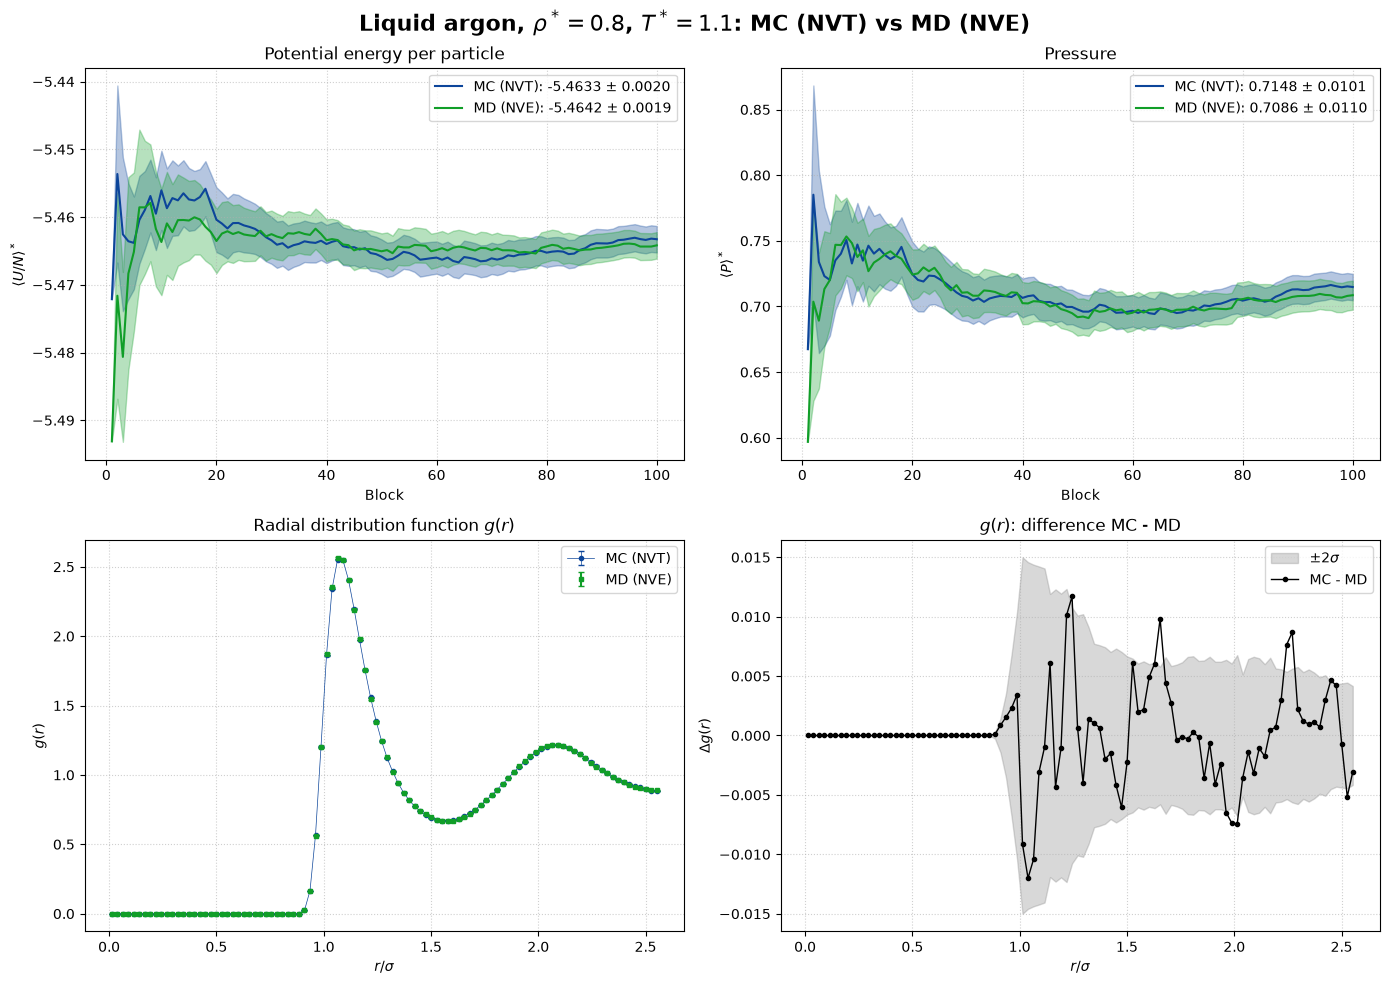

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(r'Liquid argon, $\rho^*=0.8$, $T^*=1.1$: MC (NVT) vs MD (NVE)', fontsize=16)

# U/N and P
final = {}
for ax, (name, ylabel, title) in zip(axs[0], [("potential_energy", r'$\langle U/N\rangle^*$', 'Potential energy per particle'),
                                              ("pressure",         r'$\langle P\rangle^*$',   'Pressure')]):
    for tag in ("MC", "MD"):
        b, _, ave, err = load_blocks(name, tag)
        final[name, tag] = (ave[-1], err[-1])        # last block: average over all blocks and its error
        ax.plot(b, ave, color=col[tag], label=f"{lab[tag]}: {ave[-1]:.4f} ± {err[-1]:.4f}")
        ax.fill_between(b, ave - err, ave + err, color=col[tag], alpha=0.3)
    ax.set_title(title); ax.set_xlabel('Block'); ax.set_ylabel(ylabel)
    ax.grid(True, ls=':', alpha=0.6); ax.legend()

# g(r)
r, g_mc, e_mc = load_gofr("MC")
_, g_md, e_md = load_gofr("MD")
axs[1, 0].errorbar(r, g_mc, e_mc, fmt='o',ls = '-', lw = 0.5, ms=3, capsize=2, color=col["MC"], label=lab["MC"])
axs[1, 0].errorbar(r, g_md, e_md, fmt='s', ms=3, capsize=2, color=col["MD"], label=lab["MD"])
axs[1, 0].set_title('Radial distribution function $g(r)$')
axs[1, 0].set_xlabel(r'$r/\sigma$'); axs[1, 0].set_ylabel('$g(r)$')

# g(r) difference MC and MD plus combined error 
diff, sig = g_mc - g_md, np.sqrt(e_mc**2 + e_md**2)
axs[1, 1].fill_between(r, -2 * sig, 2 * sig, color='gray', alpha=0.3, label=r'$\pm 2\sigma$')
axs[1, 1].plot(r, diff, 'k.-', lw=1, label='MC - MD')
axs[1, 1].set_title('$g(r)$: difference MC - MD')
axs[1, 1].set_xlabel(r'$r/\sigma$'); axs[1, 1].set_ylabel(r'$\Delta g(r)$')

for ax in axs[1]:
    ax.grid(True, ls=':', alpha=0.6); ax.legend()
plt.tight_layout()
plt.show()

print(f"{'quantity':18s}{'MC':>20s}{'MD':>20s}{'(MC-MD)/sigma':>16s}")
for name in ("potential_energy", "pressure"):
    (a, ea), (b_, eb) = final[name, "MC"], final[name, "MD"]
    print(f"{name:18s}{a:>12.4f} ± {ea:.4f}{b_:>12.4f} ± {eb:.4f}{(a - b_) / np.hypot(ea, eb):>14.2f}")
ok = sig > 0                                          # skip empty bins (g = 0, error = 0)
print(f"g(r): {np.mean(np.abs(diff[ok]) < 2 * sig[ok]):.0%} of the bins agree within 2 sigma")
T_md = np.loadtxt(f"{folder}/temperature_MD.dat")[-1, 2:4]
print(f"MD average temperature: {T_md[0]:.4f} ± {T_md[1]:.4f}  (target 1.1)")


The potential energy per particle and the pressure obtained with the two methods agree within the statistical uncertainties: $\langle U/N\rangle=-5.4633\pm0.0020$ (MC) and $-5.4642\pm0.0019$ (MD), $\langle P\rangle=0.7148\pm0.0101$ (MC) and $0.7086\pm0.0110$ (MD). The differences are $0.0009$ and $0.0062$, which correspond to $0.3\sigma$ and $0.4\sigma$ of the combined error. The progressive averages also behave in the same way: they are compatible with each other from the first blocks toward the end where the error bands shrink as expected.

The radial distribution function is the same for the two methods: the curves are indistinguishable on the scale of the plot and their difference oscillates around zero, almost always inside the $\pm2\sigma$ band, with no systematic trend, the few points slightly outside have a statistical nature. The difference is exactly zero for $r\lesssim0.9$, where $g(r)=0$ for both methods, and the largest fluctuations ($|\Delta g|\lesssim0.015$) are found around the first peak, where $g(r)$ varies steeply and its error is larger.

In reduced units, $g(r)$ shows the typical structure of a liquid. It vanishes below $r\simeq0.9$ because of the repulsive core, it has a pronounced first peak at $r\simeq1.07$ ($g\simeq2.55$), which is the first shell of neighbours, followed by a minimum at $r\simeq1.55$ and a much weaker second peak at $r\simeq2.1$ ($g\simeq1.2$). At larger distances it tends to 1, as the correlation between particles is lost: the liquid has short-range order but no long-range order (here $g(r)$ is computed up to $L/2\simeq2.57$).

From the agreeement of these properties, we can safely assume that the two methods are describing the same thermodynamic state. The agreement is expected, since the microcanonical and canonical ensembles are equivalent for these averages in the thermodynamic limit, and here the differences, of order $1/N$, are below our statistical resolution. It also confirms that the MD simulation sits at the same temperature $T^*=1.1$ as the MC one: a temperature mismatch would show up in $U/N$ and in the pressure.